In [26]:
import time
import pubchempy as pcp
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.ensemble import (
    BaggingRegressor,
    GradientBoostingRegressor,
    IsolationForest,
    RandomForestRegressor,
    StackingRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree

RANDOM_STATE = 100626

def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

def show_metrics(name, y_true, y_pred):
    values = regression_metrics(y_true, y_pred)
    print(name)
    print(f"  RMSE: {values['RMSE']:.3f}")
    print(f"  MAE:  {values['MAE']:.3f}")
    print(f"  R²:   {values['R2']:.3f}")
    return values


# Part XVI — Hometask

## Antimicrobial QSAR challenge

Predict the antimicrobial activity value for molecules in a hidden test set using the descriptor representation prepared for this practical.

Training data:

```text
week5/antimicrobial_train_80pct.csv
```

Feature-only test data:

```text
week5/antimicrobial_test_X_20pct.csv
```

The target is `target_log10`. The test target is hidden and must not be reconstructed from the test file.

## Instructions

1. Inspect both files. Confirm the target column, molecule identifiers, SMILES column, descriptor columns, data types, duplicated molecules, missing values, pseudo-NA values, and possible assay metadata.
2. Keep identifiers and SMILES for tracking and interpretation, but exclude them and assay metadata from the predictive feature matrix. Convert pseudo-NA values to proper missing values and document the decision for imputation or removal.
3. Split the training data into development and validation partitions. Fit every imputer, scaler, selector, and model on the development data only.
4. Train and compare at least three tree-based models, for example random forest, gradient boosting, XGBoost, LightGBM, or CatBoost. Use validation MAE as the main selection metric and keep the test table untouched.
5. Inspect model errors and feature importance. Use permutation importance or another model-agnostic method and identify descriptors associated with unusually large errors or suspicious predictions.
6. Retrain the selected workflow on all labelled training data, generate one prediction for every row of the feature-only test table, and save a file keyed by `molecule_chembl_id`.

## Questions for the report

1. What data-quality problems did you find, and how did they affect preprocessing?
2. Which descriptors and metadata were excluded from modelling, and why?
3. Which model and hyperparameters gave the best validation MAE? How stable was the result across repeated splits or folds?
4. Which descriptors were most important, and can their chemical meaning explain the model behaviour?
5. Which molecules had the largest validation errors, and what possible chemical or measurement explanation can you suggest?
6. What are the main limitations of predicting the hidden antimicrobial test set from this descriptor table?

## Deliverables

- completed notebook;
- validation comparison table for at least three models;
- error and feature-importance visualisations;
- `predictions.csv` with `molecule_chembl_id` and the predicted `target_log10`;
- short answers to the six questions.


## EDA

In [68]:
train = pd.read_csv("antimicrobial_train_80pct.csv")
test = pd.read_csv("antimicrobial_test_X_20pct.csv")

In [28]:
train

,activity_id,molecule_chembl_id,pref_name,compound_name,canonical_smiles,standard_type,standard_units,assay_chembl_id,rdkit_MaxAbsEStateIndex,rdkit_MaxEStateIndex,...,rdkit_fr_sulfonamd,rdkit_fr_sulfone,rdkit_fr_term_acetylene,rdkit_fr_tetrazole,rdkit_fr_thiazole,rdkit_fr_thiocyan,rdkit_fr_thiophene,rdkit_fr_unbrch_alkane,rdkit_fr_urea,target_log10
0,946920,CHEMBL72286,NaN,NaN,O=C(c1ccccc1O)N1CCc2c(n(Cc3ccc(O)cc3)c3ccccc23)C1,MIC,ug.mL-1,CHEMBL677573,13.081525,13.081525,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.903090
1,379615,CHEMBL134905,NaN,NaN,CC(=O)NC[C@H]1CN(c2ccc3c(c2)CCCCN3C=O)C(=O)O1,MIC,ug.mL-1,CHEMBL677421,12.110715,12.110715,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030
2,16571259,CHEMBL3798190,NaN,NaN,CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCNCC3)cc21.O=[N...,MIC,ug.mL-1,CHEMBL3801691,14.494909,14.494909,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.892095
3,141787,CHEMBL320039,NaN,NaN,N[C@H]1CN(c2c(F)cc3c(=O)c(C(=O)O)cn(C4CC4)c3c2...,MIC,ug.mL-1,CHEMBL677359,15.030342,15.030342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.221849
4,551390,CHEMBL88523,NaN,NaN,O=C(OCC1=CC=C(COC(=O)c2cccnc2)SS1)c1cccnc1,MIC,ug.mL-1,CHEMBL648210,11.880338,11.880338,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8470,1198295,CHEMBL1160682,NaN,NaN,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(Sc3nc(-c4cc...,MIC,ug.mL-1,CHEMBL673662,12.395635,12.395635,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.795880
8471,952203,CHEMBL88982,NaN,NaN,NCCNC(=O)c1cc(-c2c[nH]c3ccc(Br)cc23)nc2ccccc12...,MIC,ug.mL-1,CHEMBL673511,12.647314,12.647314,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.397940
8472,1190294,CHEMBL275692,NaN,NaN,CC(=O)OCC1=C(C(=O)OC(c2ccccc2)c2ccccc2)N2C(=O)...,MIC,ug.mL-1,CHEMBL670512,13.865431,13.865431,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.522879
8473,377863,CHEMBL44431,NaN,NaN,O=C(COc1ccccc1)N[C@@H]1C(=O)N2C(C(=O)O)=C(Cl)C...,MIC,ug.mL-1,CHEMBL673753,12.167056,12.167056,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.806180


In [29]:
test

,activity_id,molecule_chembl_id,pref_name,compound_name,canonical_smiles,standard_type,standard_units,assay_chembl_id,rdkit_MaxAbsEStateIndex,rdkit_MaxEStateIndex,...,rdkit_fr_sulfide,rdkit_fr_sulfonamd,rdkit_fr_sulfone,rdkit_fr_term_acetylene,rdkit_fr_tetrazole,rdkit_fr_thiazole,rdkit_fr_thiocyan,rdkit_fr_thiophene,rdkit_fr_unbrch_alkane,rdkit_fr_urea
0,849731,CHEMBL121649,NaN,NaN,O=C(Cc1ccccc1)N[C@@H]1C(=O)N2C(C(=O)O)=C(CCO)C...,MIC,ug.mL-1,CHEMBL673564,12.247022,12.247022,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,287078,CHEMBL68208,NaN,NaN,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)[O-])=C(CSC(=S)N...,MIC,ug.mL-1,CHEMBL676864,12.092750,12.092750,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,863129,CHEMBL134718,NaN,NaN,O=C(NC[C@H]1CN(c2ccc(N3CCS(=O)(=O)CC3)c(F)c2)C...,MIC,ug.mL-1,CHEMBL679456,14.677104,14.677104,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,736683,CHEMBL346824,NaN,NaN,O=C(NNc1ccccc1)c1ccc(NC(=S)Nc2ccc(NC(=S)Nc3ccc...,MIC,ug.mL-1,CHEMBL649395,12.406924,12.406924,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1219627,CHEMBL129494,NaN,NaN,CCCCCCCCCCCCOC(=O)c1cc(O)cc(O)c1O,MIC,ug.mL-1,CHEMBL809819,11.825847,11.825847,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2114,5296294,CHEMBL1459,N-DESMETHYL LEVOFLOXACIN,N-DESMETHYL LEVOFLOXACIN,C[C@H]1COc2c(N3CCNCC3)c(F)cc3c(=O)c(C(=O)O)cn1c23,MIC,ug.mL-1,CHEMBL1691259,14.879699,14.879699,...,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2115,162934,CHEMBL284267,NaN,NaN,C=C1/C=C(\C)[C@H](CC)OC(=O)[C@H](C)C(=O)[C@@](...,MIC,ug.mL-1,CHEMBL648394,12.667220,12.667220,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2116,847994,CHEMBL424025,NaN,NaN,CCCCCCCC(=O)c1ccc(O)c(C(=O)Nc2ccc(Br)cc2)c1,MIC,ug.mL-1,CHEMBL638796,12.432809,12.432809,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0
2117,824366,CHEMBL146053,NaN,NaN,Cc1c(N2CCC(O)CC2)ccc2c(=O)c(C(=O)O)cn(C3CC3)c12,MIC,ug.mL-1,CHEMBL674852,12.607102,12.607102,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [30]:
print(set(train.columns).difference(set(test.columns)))

{'target_log10'}


only difference is our target in the train dataset

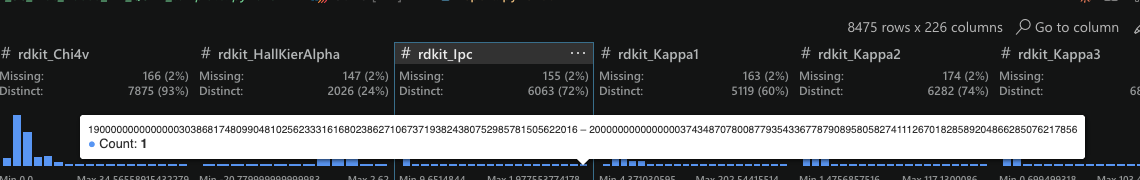

one value for rdkit_lpc seem really odd, enourmously huge, i thought about removing it, but others also not small, looks like this particular param(lpc) can have huge values, mb should be normalized. 
there are 0's in the columns rdkit_*_VSA* but i've looked into it, they can be 0  
other columns with 0 are "_count" columns, and they also can be 0  
i didnt see any inf or other pseudo-NA data, we can conut on NA  
units, smiles, ids are provided and non NA
assay might be a grouping wariable

without log10 decision tree doesnt work as the number is too big

In [69]:
train["rdkit_Ipc"] = np.log10(train["rdkit_Ipc"])
test["rdkit_Ipc"] = np.log10(test["rdkit_Ipc"])

In [32]:
assay_counts = train["assay_chembl_id"].value_counts()
print(assay_counts.describe())

fig = px.histogram(x=assay_counts.values, nbins=50, log_y=True,
                   labels={"x": "molecules per assay"},
                   title=f"Molecules per assay ({assay_counts.size} assays)")
fig.show()

fig = px.bar(x=assay_counts.head(30).index, y=assay_counts.head(30).values,
             labels={"x": "assay_chembl_id", "y": "count"},
             title="Top 30 assays by molecule count")
fig.update_layout(xaxis_tickangle=-90)
fig.show()

count    1017.000000
mean        8.333333
std        11.778049
min         1.000000
25%         1.000000
50%         4.000000
75%        11.000000
max       129.000000
Name: count, dtype: float64


In [33]:
desc_cols = [c for c in train.columns if c.startswith("rdkit_")]

print("full rows:", train.duplicated().sum())
print("molecule_chembl_id:", train["molecule_chembl_id"].duplicated().sum())
print("canonical_smiles:", train["canonical_smiles"].duplicated().sum())
print("descriptors only:", train.duplicated(subset=desc_cols).sum())
print("test ids in train:", test["molecule_chembl_id"].isin(train["molecule_chembl_id"]).sum())
print("test smiles in train:", test["canonical_smiles"].isin(train["canonical_smiles"]).sum())

full rows: 0
molecule_chembl_id: 0
canonical_smiles: 0
descriptors only: 0
test ids in train: 0
test smiles in train: 0


In [34]:
na_pct = (train.isna().mean() * 100).sort_values(ascending=False)
na_pct = na_pct[na_pct > 0]

fig = px.bar(x=na_pct.index, y=na_pct.values,
             labels={"x": "feature", "y": "% missing"},
             title="Missing values per feature (% of rows)")
fig.update_layout(xaxis_tickangle=-90, height=600)
fig.show()


In [35]:
na_pct = (test.isna().mean() * 100).sort_values(ascending=False)
na_pct = na_pct[na_pct > 0]

fig = px.bar(x=na_pct.index, y=na_pct.values,
             labels={"x": "feature", "y": "% missing"},
             title="Missing values per feature (% of rows)")
fig.update_layout(xaxis_tickangle=-90, height=600)
fig.show()


The distribution of NA between test and train seem similar, most of the features are present with 5% na most, imputter on train data

In [70]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

id_cols = ["activity_id", "molecule_chembl_id", "pref_name", "compound_name", "canonical_smiles"]
meta_cols = ["standard_type", "standard_units", "assay_chembl_id"]
target = "target_log10"

feature_cols = [c for c in train.columns if c not in id_cols + meta_cols + [target]]

X = train[feature_cols]
y = train[target]
X_test = test[feature_cols]

imputer = IterativeImputer(random_state=RANDOM_STATE)

In [37]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

pca_pipe = Pipeline([
    ("imputer", IterativeImputer(random_state=RANDOM_STATE)),
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=RANDOM_STATE)),
])
X_pca = pca_pipe.fit_transform(X)
pca = pca_pipe.named_steps["pca"]

X_scaled = pca_pipe[:-1].transform(X)
X_tsne = TSNE(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)

fig = make_subplots(rows=1, cols=2, subplot_titles=(
    f"PCA (PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%})",
    "t-SNE",
))
fig.add_scatter(x=X_pca[:, 0], y=X_pca[:, 1], mode="markers",
                marker=dict(color=y, coloraxis="coloraxis", size=4), row=1, col=1)
fig.add_scatter(x=X_tsne[:, 0], y=X_tsne[:, 1], mode="markers",
                marker=dict(color=y, coloraxis="coloraxis", size=4), row=1, col=2)
fig.update_layout(coloraxis=dict(colorbar_title="target_log10"), showlegend=False,
                  title="Descriptors colored by target", height=500)
fig.show()

n = 30
fig = go.Figure()
fig.add_bar(x=np.arange(1, n + 1), y=pca.explained_variance_ratio_[:n], name="per PC")
fig.add_scatter(x=np.arange(1, n + 1), y=np.cumsum(pca.explained_variance_ratio_[:n]),
                mode="lines+markers", name="cumulative")
fig.update_layout(title="Elbow plot", xaxis_title="PC", yaxis_title="explained variance ratio")
fig.show()


poor pca components, non linear dependensies
in tsne top left cluster seem to have a higher target values on average

In [38]:
corr = train[feature_cols + [target]].corr()

fig = px.imshow(corr, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Correlation matrix (features + target)")
fig.update_layout(height=1000, width=1000)
fig.show()

In [72]:
corr = train[feature_cols + [target]].corr(method="spearman")

fig = px.imshow(corr, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Correlation matrix (features + target)")
fig.update_layout(height=1000, width=1000)
fig.show()

target seem not to correlate with any feature directly, some values correlate with each other, but they often describe similar things like "PEOE_VSA1–14: surface area falling into each partial-charge bin." and "SMR_VSA1–10: surface area falling into each molar-refractivity (polarizability) bin."

In [39]:
from sklearn.model_selection import GroupShuffleSplit

groups = train["assay_chembl_id"]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
dev_idx, val_idx = next(gss.split(X, y, groups))

X_dev, X_val = X.iloc[dev_idx], X.iloc[val_idx]
y_dev, y_val = y.iloc[dev_idx], y.iloc[val_idx]
groups_dev = groups.iloc[dev_idx]

In [40]:
from sklearn.linear_model import LinearRegression

lr = Pipeline([
    ("imputer", IterativeImputer(random_state=RANDOM_STATE)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
lr.fit(X_dev, y_dev)

lr_metrics = show_metrics("Linear regression", y_val, lr.predict(X_val))

Linear regression
  RMSE: 1.055
  MAE:  0.841
  R²:   0.202


In [ ]:

tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeRegressor(max_depth=5, min_samples_leaf=8, random_state=RANDOM_STATE))])
tree.fit(X_dev, y_dev)


tree_metrics = show_metrics("decision tree", y_val, tree.predict(X_val))

decision tree
  RMSE: 1.111
  MAE:  0.876
  R²:   0.115


it performed worse than regular linear model

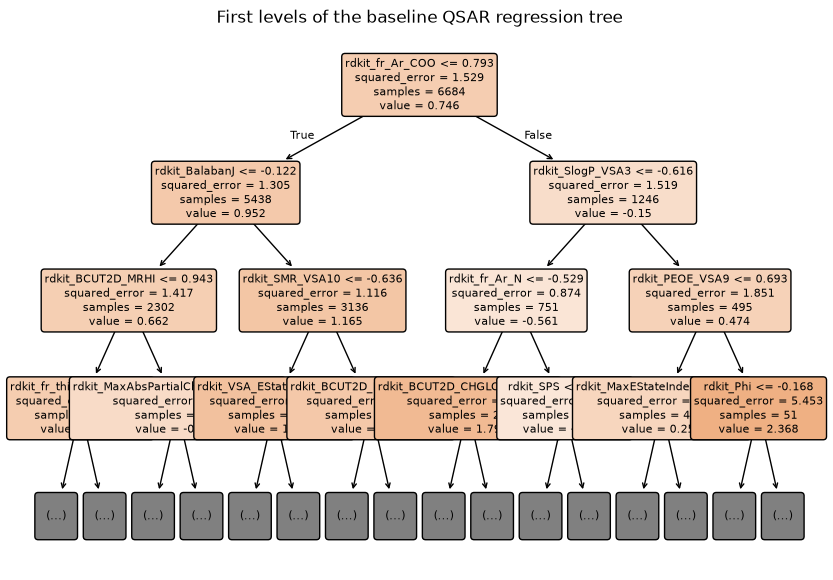

In [44]:
plt.figure(figsize=(10, 7))
plot_tree(
    tree.named_steps["model"],
    max_depth=3,
    feature_names=feature_cols,
    filled=True,
    rounded=True,
    fontsize=8,)
plt.title("First levels of the baseline QSAR regression tree")
plt.show()


In [55]:
X_dev_imputed = pd.DataFrame(imputer.fit_transform(X_dev), columns=feature_cols, index=X_dev.index)
X_val_imputed = pd.DataFrame(imputer.transform(X_val), columns=feature_cols, index=X_val.index)

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=250,
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_model.fit(X_dev_imputed, y_dev)
rf_metrics = show_metrics("rf", y_val, rf_model.predict(X_val))

rf
  RMSE: 0.963
  MAE:  0.782
  R²:   0.336


In [53]:
import optuna
from sklearn.model_selection import GroupKFold

def rf_objective(trial):
    model = RandomForestRegressor(
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
        max_depth=trial.suggest_int("max_depth", 5, 30),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        max_features=trial.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]),
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    scores = cross_val_score(
        model, X_dev_imputed, y_dev, groups=groups_dev, cv=GroupKFold(n_splits=5),
        scoring="neg_mean_absolute_error", n_jobs=-1,
    )
    return -scores.mean()

rf_study = optuna.create_study(direction="minimize")
rf_study.optimize(rf_objective, n_trials=30, show_progress_bar=False)
print("Best RF MAE:", rf_study.best_value)
print("Best RF parameters:", rf_study.best_params)

[I 2026-11-11 15:12:30,237] A new study created in memory with name: no-name-563a709a-08fd-4f88-abe0-03efcef49f71
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multipr

Best RF MAE: 0.8349403186146155
Best RF parameters: {'n_estimators': 599, 'max_depth': 23, 'min_samples_leaf': 7, 'max_features': 'sqrt'}


In [ ]:
rf_model_best = RandomForestRegressor(
    n_estimators=599,
    max_features="sqrt",
    min_samples_leaf=7,
    max_depth=23,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_model_best.fit(X_dev_imputed, y_dev)
rf_metrics_best = show_metrics("rf", y_val, rf_model_best.predict(X_val))

rf
  RMSE: 0.959
  MAE:  0.781
  R²:   0.341


In [49]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, objective="reg:squarederror",
        random_state=RANDOM_STATE, n_jobs=-1)
xgb_model.fit(X_dev_imputed, y_dev)
show_metrics("XGBoost", y_val, xgb_model.predict(X_val_imputed))

XGBoost
  RMSE: 0.955
  MAE:  0.776
  R²:   0.347


{'RMSE': np.float64(0.954814005239264),
 'MAE': 0.7760942127572826,
 'R2': 0.3468881876767981}

In [ ]:
def xgb_objective(trial):
    model = XGBRegressor(
        n_estimators=trial.suggest_int("n_estimators", 200, 1000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 8),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 0.1, 10, log=True),
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1,
    )
    scores = cross_val_score(
        model, X_dev_imputed, y_dev, groups=groups_dev, cv=GroupKFold(n_splits=5),
        scoring="neg_mean_absolute_error", n_jobs=-1,
    )
    return -scores.mean()

xgb_study = optuna.create_study(direction="minimize")
xgb_study.optimize(xgb_objective, n_trials=30, show_progress_bar=False)
print("Best XGBoost MAE:", xgb_study.best_value)
print("Best XGBoost parameters:", xgb_study.best_params)

/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/late

{'subsample': 0.8, 'reg_lambda': 1.0, 'n_estimators': 600, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.5} 0.8474192979542989
XGBoost tuned
  RMSE: 0.961
  MAE:  0.790
  R²:   0.339


In [56]:
xgb_model = XGBRegressor(
        n_estimators=600, learning_rate=0.01, max_depth=3,
        min_child_weight=10, subsample=0.8, colsample_bytree=0.5,
        reg_lambda=1.0, objective="reg:squarederror",
        random_state=RANDOM_STATE, n_jobs=-1)
xgb_model.fit(X_dev_imputed, y_dev)
show_metrics("XGBoost", y_val, xgb_model.predict(X_val_imputed))

XGBoost
  RMSE: 0.961
  MAE:  0.790
  R²:   0.339


{'RMSE': np.float64(0.9606564883577365),
 'MAE': 0.7895929610226756,
 'R2': 0.33887098413044037}

In [50]:
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        max_depth=-1, subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, verbosity=-1)

lgbm_model.fit(X_dev_imputed, y_dev)
show_metrics("LightGBM", y_val, lgbm_model.predict(X_val_imputed))

LightGBM
  RMSE: 0.959
  MAE:  0.767
  R²:   0.341


{'RMSE': np.float64(0.9587875081294046),
 'MAE': 0.7668285630722276,
 'R2': 0.34144096641492305}

In [59]:
def lgbm_objective(trial):
    model = LGBMRegressor(
        n_estimators=trial.suggest_int("n_estimators", 200, 1000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 15, 127),
        min_child_samples=trial.suggest_int("min_child_samples", 2, 50),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 0.1, 10, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        random_state=RANDOM_STATE, verbosity=-1,
    )
    scores = cross_val_score(
        model, X_dev_imputed, y_dev, groups=groups_dev, cv=GroupKFold(n_splits=5),
        scoring="neg_mean_absolute_error", n_jobs=-1,
    )
    return -scores.mean()

lgbm_study = optuna.create_study(direction="minimize")
lgbm_study.optimize(lgbm_objective, n_trials=30, show_progress_bar=False)
print("Best LightGBM MAE:", lgbm_study.best_value)
print("Best LightGBM parameters:", lgbm_study.best_params)

[I 2026-11-11 17:59:14,380] A new study created in memory with name: no-name-30b5b24d-b5f3-422d-aa4f-75382fdaeedf
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multipr

Best LightGBM MAE: 0.8427808838635334
Best LightGBM parameters: {'n_estimators': 210, 'learning_rate': 0.011162129319704145, 'num_leaves': 73, 'min_child_samples': 47, 'colsample_bytree': 0.44553304283865675, 'reg_lambda': 2.8478259467894462, 'subsample': 0.6882930244156138}


In [60]:
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
        n_estimators=210, learning_rate=0.011, num_leaves=73, min_child_samples=47,
        max_depth=-1, subsample=0.7, colsample_bytree=0.45, reg_lambda=2.84,
        random_state=RANDOM_STATE, verbosity=-1)

lgbm_model.fit(X_dev_imputed, y_dev)
show_metrics("LightGBM", y_val, lgbm_model.predict(X_val_imputed))

LightGBM
  RMSE: 0.962
  MAE:  0.786
  R²:   0.337


{'RMSE': np.float64(0.9618505594954113),
 'MAE': 0.7856192128368715,
 'R2': 0.3372264302042858}

In [61]:
models = {"Random Forest": rf_model_best, "XGBoost": xgb_model, "LightGBM": lgbm_model}

for name, model in models.items():
    impurity_importance = pd.Series(
        model.feature_importances_, index=feature_cols, name="importance"
    ).sort_values(ascending=False)

    importance_plot_df = (
        impurity_importance.head(20)
        .sort_values()
        .reset_index()
        .rename(columns={"index": "descriptor"})
    )
    importance_fig = px.bar(
        importance_plot_df, x="importance", y="descriptor",
        orientation="h", title=f"{name}: top descriptors by impurity importance",
    )
    importance_fig.show()

In [62]:
top20 = {name: set(pd.Series(model.feature_importances_, index=feature_cols).nlargest(20).index)
         for name, model in models.items()}
set.intersection(*top20.values())

{'rdkit_BalabanJ',
 'rdkit_MaxAbsEStateIndex',
 'rdkit_MinAbsPartialCharge',
 'rdkit_SlogP_VSA3'}

In [64]:
perm_results = {}

for name, model in models.items():
    perm = permutation_importance(
        model,
        X_val_imputed,
        y_val,
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    perm_results[name] = pd.Series(perm.importances_mean, index=feature_cols)

    perm_plot_df = pd.DataFrame({
        "feature": feature_cols,
        "mean_score_change": perm.importances_mean,
        "sd": perm.importances_std,
    }).nlargest(20, "mean_score_change").sort_values("mean_score_change")

    perm_fig = px.bar(
        perm_plot_df,
        x="mean_score_change",
        y="feature",
        orientation="h",
        error_x="sd",
        title=f"{name}: permutation importance on validation molecules",
        labels={"mean_score_change": "Increase in MAE after shuffling", "feature": "Descriptor"},
    )
    perm_fig.add_vline(x=0, line_dash="dash", line_color="gray")
    perm_fig.show()

perm_df = pd.DataFrame(perm_results)
perm_df["mean"] = perm_df.mean(axis=1)
perm_df = perm_df.sort_values("mean", ascending=False)

perm_top20 = {name: set(perm_df[name].nlargest(20).index) for name in models}
print("Top-20 shared by all models:", set.intersection(*perm_top20.values()))

/Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/neprog/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)


Top-20 shared by all models: {'rdkit_MaxEStateIndex', 'rdkit_FpDensityMorgan3', 'rdkit_BCUT2D_MRLOW', 'rdkit_SMR_VSA10', 'rdkit_fr_pyridine', 'rdkit_SlogP_VSA3', 'rdkit_EState_VSA4', 'rdkit_MaxAbsEStateIndex', 'rdkit_AvgIpc', 'rdkit_fr_Ar_COO', 'rdkit_NumSaturatedCarbocycles'}


In [65]:
summary_df = pd.DataFrame({
    "Linear regression": regression_metrics(y_val, lr.predict(X_val)),
    "Decision tree": regression_metrics(y_val, tree.predict(X_val)),
    "Random Forest": regression_metrics(y_val, rf_model_best.predict(X_val_imputed)),
    "XGBoost": regression_metrics(y_val, xgb_model.predict(X_val_imputed)),
    "LightGBM": regression_metrics(y_val, lgbm_model.predict(X_val_imputed)),
}).T.sort_values("MAE")

summary_df

,RMSE,MAE,R2
Random Forest,0.957556,0.779128,0.343132
LightGBM,0.961851,0.785619,0.337226
XGBoost,0.960656,0.789593,0.338871
Linear regression,1.055283,0.841389,0.202211
Decision tree,1.111185,0.876417,0.115450


In [66]:
ensemble_pred = np.mean([
    rf_model_best.predict(X_val_imputed),
    xgb_model.predict(X_val_imputed),
    lgbm_model.predict(X_val_imputed),
], axis=0)

summary_df.loc["Ensemble (avg)"] = regression_metrics(y_val, ensemble_pred)
summary_df = summary_df.sort_values("MAE")
summary_df

,RMSE,MAE,R2
Random Forest,0.957556,0.779128,0.343132
Ensemble (avg),0.954729,0.781376,0.347004
LightGBM,0.961851,0.785619,0.337226
XGBoost,0.960656,0.789593,0.338871
Linear regression,1.055283,0.841389,0.202211
Decision tree,1.111185,0.876417,0.115450


In [71]:
final_imputer = IterativeImputer(random_state=RANDOM_STATE)
X_imputed = pd.DataFrame(final_imputer.fit_transform(X), columns=feature_cols, index=X.index)
X_test_imputed = pd.DataFrame(final_imputer.transform(X_test), columns=feature_cols, index=X_test.index)

final_model = RandomForestRegressor(
    n_estimators=599,
    max_features="sqrt",
    min_samples_leaf=7,
    max_depth=23,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
final_model.fit(X_imputed, y)

predictions = pd.DataFrame({
    "molecule_chembl_id": test["molecule_chembl_id"],
    "target_log10": final_model.predict(X_test_imputed),
})
predictions.to_csv("predictions.csv", index=False)

print(predictions.shape, predictions["molecule_chembl_id"].is_unique)
predictions.head()

(2119, 2) True


,molecule_chembl_id,target_log10
0,CHEMBL121649,0.718486
1,CHEMBL68208,0.967028
2,CHEMBL134718,0.518223
3,CHEMBL346824,1.401654
4,CHEMBL129494,1.600293


In [73]:
val_errors = train.loc[X_val.index, ["molecule_chembl_id", "pref_name", "canonical_smiles", "assay_chembl_id", target]].copy()
val_errors["predicted"] = rf_model_best.predict(X_val_imputed)
val_errors["abs_error"] = (val_errors[target] - val_errors["predicted"]).abs()
val_errors.sort_values("abs_error", ascending=False).head(10)

,molecule_chembl_id,pref_name,canonical_smiles,assay_chembl_id,target_log10,predicted,abs_error
179,CHEMBL530,AMDINOCILLIN,CC1(C)S[C@@H]2[C@H](/N=C/N3CCCCCC3)C(=O)N2[C@H...,CHEMBL670512,-2.397940,1.195050,3.592990
4737,CHEMBL155786,NaN,C[C@@H]1C[C@H](C)[C@@H](C)O[C@@]1(O)COC(=O)c1c...,CHEMBL649457,-1.698970,1.433708,3.132678
1830,CHEMBL128956,NaN,CCC[C@H](NC(=O)CNC)C(=O)N[C@@H](CCC)C(=O)N[C@H...,CHEMBL696268,-1.823909,1.246675,3.070584
6232,CHEMBL2079575,NaN,O=c1[nH]c(=O)n([C@H]2C[C@H](O)[C@@H](CO)O2)cc1...,CHEMBL690182,-1.522879,1.315862,2.838741
8279,CHEMBL382560,NaN,Nc1cccc(-c2cc3c(cc2F)c(=O)c2c(=O)[nH]sc2n3C2CC...,CHEMBL865595,-2.397940,0.347720,2.745660
7883,CHEMBL154527,NaN,C[C@@H]1C[C@H](C)[C@@H](C)O[C@@]1(O)COC(=O)Nc1...,CHEMBL649457,-1.301030,1.275119,2.576149
3262,CHEMBL9,NORFLOXACIN,CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCNCC3)cc21,CHEMBL3738528,2.397940,-0.158425,2.556365
2978,CHEMBL275939,NaN,CC(=O)OCC1=C(C(=O)OC(c2ccccc2)c2ccccc2)N2C(=O)...,CHEMBL670512,-1.795880,0.719082,2.514962
244,CHEMBL2368014,NaN,NCCN(CCN)CCNC(=O)[C@H]1NC(=O)[C@H]2NC(=O)[C@H]...,CHEMBL675150,-0.903090,1.573413,2.476503
290,CHEMBL2368018,NaN,NCCNCCCNCCNC(=O)[C@H]1NC(=O)[C@H]2NC(=O)[C@H](...,CHEMBL675150,-0.903090,1.571542,2.474632


In [78]:
error_corr = X_val_imputed.corrwith(val_errors["abs_error"]).sort_values(key=abs, ascending=False)

px.bar(error_corr.head(20).sort_values(), orientation="h",
       title="Top 20 features correlated with absolute validation error",
       labels={"value": "Pearson r", "index": "Descriptor"}).update_layout(showlegend=False).show()

/Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


1. What data-quality problems did you find, and how did they affect preprocessing?
na was not that big of a problem, max na per feature under 5% could be imputed
2. Which descriptors and metadata were excluded from modelling, and why?
descriptors - ids removed, metadata - assay id left. to prevent models from remembering the molecules, assay id for grouping
3. Which model and hyperparameters gave the best validation MAE? How stable was the result across repeated splits or folds?
rf {'n_estimators': 599, 'max_depth': 23, 'min_samples_leaf': 7, 'max_features': 'sqrt'}
4. Which descriptors were most important, and can their chemical meaning explain the model behaviour?
depends on the model, but electronegativity rdkit_MaxEStateIndex/rdkit_MaxAbsEStateIndex is there. make sense - more electronegative

```
rdkit_fr_Ar_COO is the number of carboxylic acid groups (–COOH) attached directly to an aromatic ring.

It matters here because fluoroquinolones (ciprofloxacin, levofloxacin and others) all carry this group on the quinolone ring, and it's essential for binding bacterial DNA gyrase. The feature effectively flags the quinolone class, which tends to be highly potent.

```
5. Which molecules had the largest validation errors, and what possible chemical or measurement explanation can you suggest?
table above, not sure why, the first one is pretty old, one assay id is shown twice. often target is negative(or highly positive) and we miss that info
6. What are the main limitations of predicting the hidden antimicrobial test set from this descriptor table?
split is not done by us, we dont know the distribution, whether the grouping was applied